In [3]:
import pandas as pd
import numpy as np
import sqlite3
from pathlib import Path
import matplotlib.pyplot as plt

# Task 0
Data extraction: get the data from 3 tables & combine it into single `.csv` file.
After that read this file using pandas to create Dataframe.
So it will be all joined data in 1 dataframe. Quick check - should be 74818 rows in it.

In [4]:
project_dir = Path.cwd()

if not (project_dir / "db.sqlite3").exists():
    project_dir = project_dir.parent

db_path = project_dir / "db.sqlite3"
csv_path = project_dir / "restaurant_data.csv"

query = """
SELECT
    oi.id AS "Order Item ID",
    o.id AS "Order ID",
    o.datetime AS "Order Datetime",
    p.id AS "Product ID",
    p.name AS "Product Name",
    p.price AS "Product Price",
    oi.quantity AS "Quantity"
FROM restaurant_orderitem AS oi
JOIN restaurant_order AS o ON oi.order_id = o.id
JOIN restaurant_product AS p ON oi.product_id = p.id
ORDER BY oi.id
"""

with sqlite3.connect(db_path) as connection:
    data = pd.read_sql_query(query, connection)

data.to_csv(csv_path, index=False)

df = pd.read_csv(csv_path, parse_dates=["Order Datetime"])

df.head()

,Order Item ID,Order ID,Order Datetime,Product ID,Product Name,Product Price,Quantity
0,1,1,2019-08-03 20:25:00,6,Plain Papadum,0.80,2
1,2,1,2019-08-03 20:25:00,240,King Prawn Balti,12.95,1
2,3,1,2019-08-03 20:25:00,19,Garlic Naan,2.95,1
3,4,1,2019-08-03 20:25:00,36,Mushroom Rice,3.95,1
4,5,1,2019-08-03 20:25:00,111,Paneer Tikka Masala,8.95,1


# Task 1
Get Top 10 most popular products in restaurant sold by Quantity.
Count how many times each product was sold and create a pie chart with percentage of popularity (by quantity) for top 10 of them.

Example:

![pie chart](../demo/pie.png)

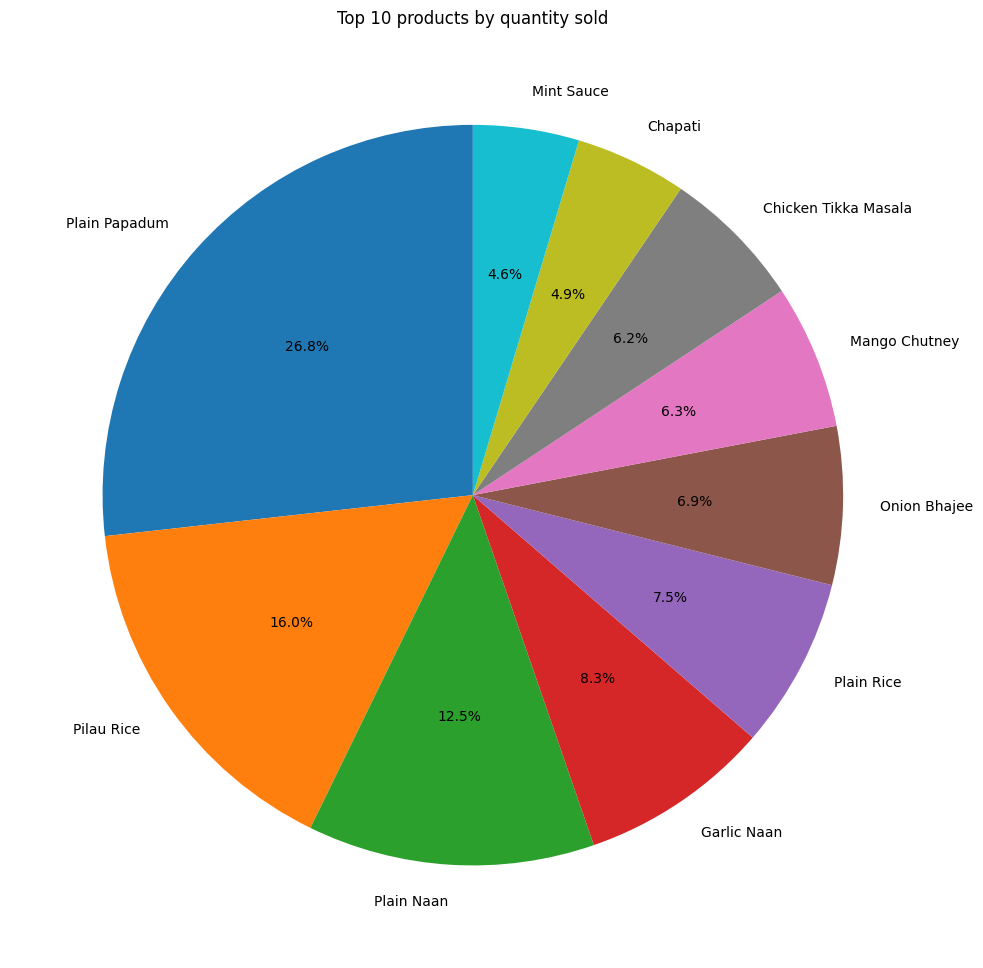

In [6]:
top_quantity = (df.groupby("Product Name")["Quantity"].sum().nlargest(10))
top_quantity.plot.pie(autopct="%1.1f%%", startangle=90, figsize=(10, 10), ylabel="", title="Top 10 products by quantity sold")

plt.tight_layout()
plt.show()

# Task 2
Calculate `Item Price` (Product Price * Quantity) for each Order Item in dataframe.
And Make the same Top 10 pie chart, but this time by `Item Price`. So this chart should describe not the most popular products by quantity, but which products (top 10) make the most money for restaurant. It should be also with percentage.

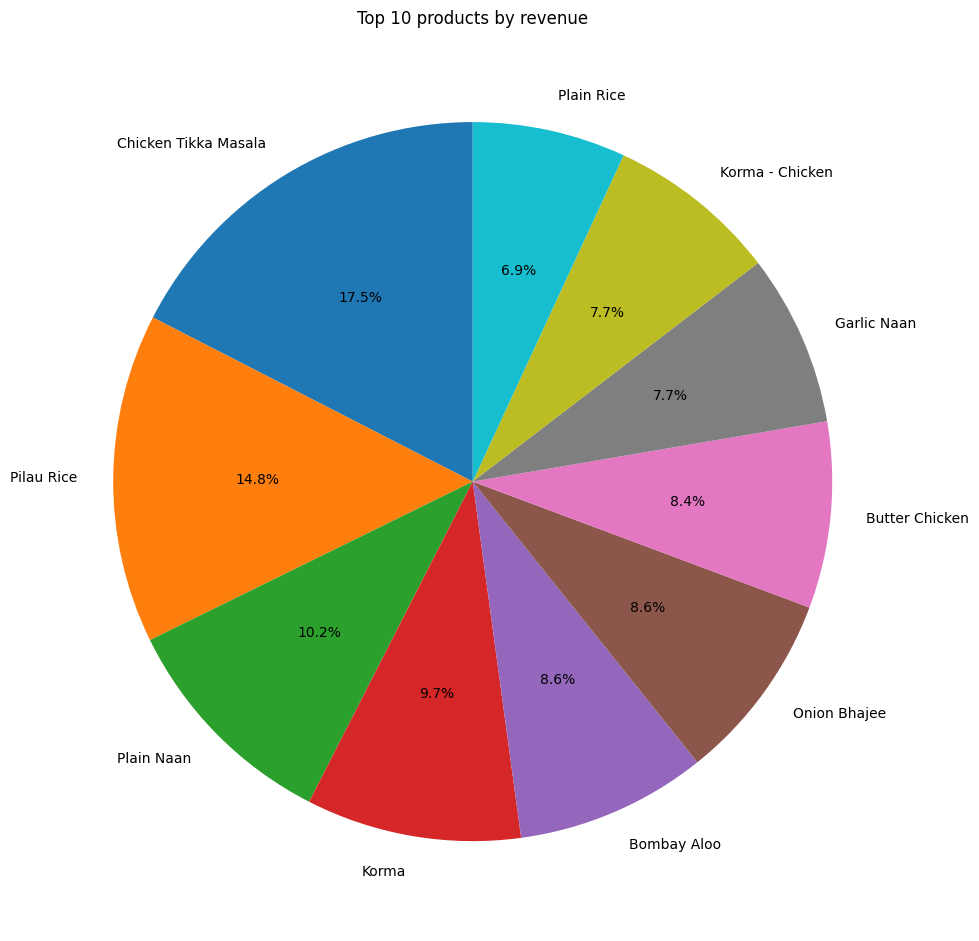

In [7]:
df["Item Price"] = df["Product Price"] * df["Quantity"]
top_revenue = (df.groupby("Product Name")["Item Price"].sum().nlargest(10))
top_revenue.plot.pie(autopct="%1.1f%%", startangle=90, figsize=(10, 10), ylabel="", title="Top 10 products by revenue")

plt.tight_layout()
plt.show()

# Task 3
Calculate `Order Hour` based on `Order Datetime`, which will tell about the specific our the order was created (from 0 to 23). Using `Order Hour` create a bar chart, which will tell the total restaurant income based on the hour order was created. So on x-axis - it will be values from 0 to 23 (hours), on y-axis - it will be the total sum of order prices, which were sold on that hour.

Example:

![bar chart](../demo/bar.png)

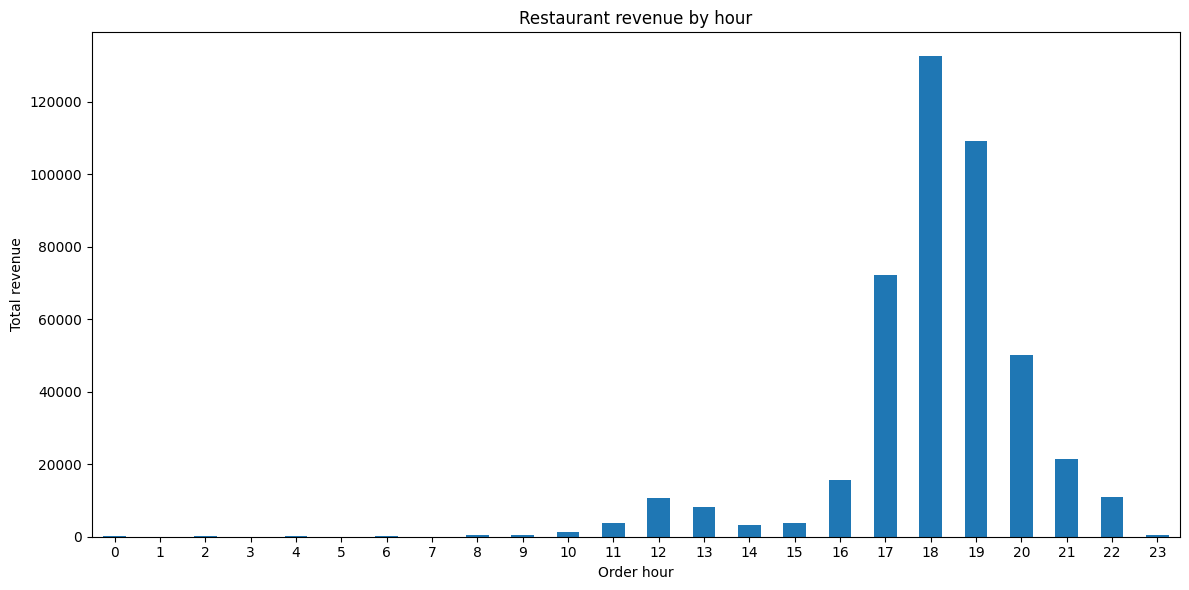

In [9]:
df["Order Hour"] = df["Order Datetime"].dt.hour
hourly_revenue = (df.groupby("Order Hour")["Item Price"].sum().reindex(range(24), fill_value=0))

ax = hourly_revenue.plot.bar(figsize=(12, 6), rot=0, title="Restaurant revenue by hour")
ax.set_xlabel("Order hour")
ax.set_ylabel("Total revenue")

plt.tight_layout()
plt.show()

# Task 4
Make similar bar chart, but right now with `Order Day Of The Week` (from Monday to Sunday), and also analyze total restaurant income by each day of the week.

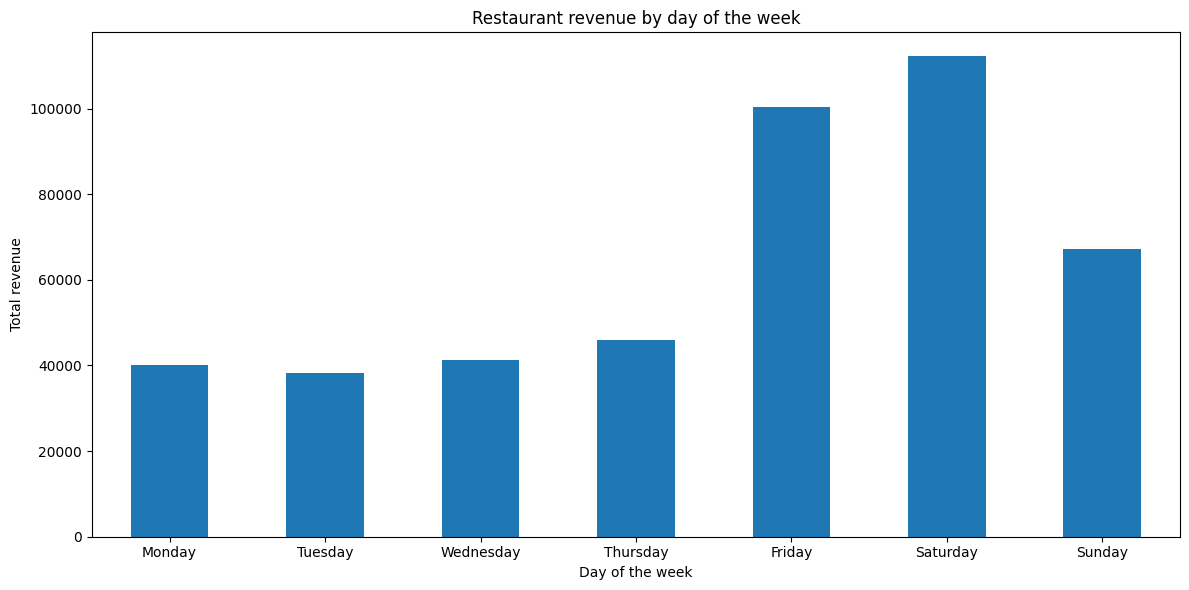

Order Day Of The Week
Monday        40008.30
Tuesday       38145.65
Wednesday     41246.20
Thursday      46021.55
Friday       100339.15
Saturday     112191.65
Sunday        67105.95
Name: Item Price, dtype: float64


In [10]:
df["Order Day Of The Week"] = df["Order Datetime"].dt.day_name()
weekdays = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_revenue = (df.groupby("Order Day Of The Week")["Item Price"].sum().reindex(weekdays, fill_value=0))

ax = weekday_revenue.plot.bar(figsize=(12, 6), rot=0, title="Restaurant revenue by day of the week")
ax.set_xlabel("Day of the week")
ax.set_ylabel("Total revenue")

plt.tight_layout()
plt.show()
print(weekday_revenue.round(2))